# Fig. S1: electronic Raman scattering spectra


    High-wavenumber Raman spectra of the six-layer flake at 488 nm excitation, recorded with crossed
    and with parallel polarizers (WITec confocal Raman system, 600 lines/mm grating). Crossed polarizers
    transmit the electronic Raman scattering (ERS) signal, parallel polarizers filter it out and leave the
    phonon overtones. The −1 → +1 ERS transition of the (+⁵) stacking sits at about 4008 cm⁻¹.

    The data set holds the two spectra of the defect-free (+⁵) region that were exported from the
    measurement (Spectrum 051, crossed, and Spectrum 052, parallel; cosmic rays removed). The spectra of
    the (+⁴−) region and of the mixed area shown in Fig. S1 are not part of this export.

    Data: `ERS_ABC6_488nm_crossed_Spectrum051.txt`, `ERS_ABC6_488nm_parallel_Spectrum052.txt`
    (two columns: Raman shift in cm⁻¹, counts) and the WITec `*_Information.txt` files with the
    acquisition parameters.


Paper: Kandrai, K. *et al.* One-way electron mirrors from single-layer stacking shifts in rhombohedral graphite. Preprint at https://arxiv.org/abs/2610.20905 (2026).

In [1]:
import os
import sys
import requests
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

In [2]:
print('python', sys.version.split()[0])
print('numpy', np.__version__)
print('matplotlib', matplotlib.__version__)

python 3.13.5
numpy 2.1.3
matplotlib 3.10.0


In [3]:
# figure style of the paper: scienceplots if it is installed, plain matplotlib otherwise
try:
    import scienceplots  # noqa: F401
    plt.style.use(['science', 'no-latex', 'nature', 'std-colors'])
except ImportError:
    pass
matplotlib.rcParams['pdf.fonttype'] = 42   # editable text in Inkscape / Illustrator
matplotlib.rcParams['ps.fonttype'] = 42
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['figure.dpi'] = 110

In [4]:
# Data files are downloaded from Zenodo into DATA_DIR if they are not there yet.
ZENODO_RECORD = '23419464'   # record number of the data set, https://zenodo.org/records/<ZENODO_RECORD>
DATA_DIR = 'data'

FILES = ['ERS_ABC6_488nm_crossed_Spectrum051.txt', 'ERS_ABC6_488nm_parallel_Spectrum052.txt', 'ERS_ABC6_488nm_crossed_Spectrum051_Information.txt', 'ERS_ABC6_488nm_parallel_Spectrum052_Information.txt']


def get_data(filename, record=ZENODO_RECORD, data_dir=DATA_DIR):
    """Return the local path of a data file, downloading it from Zenodo first if needed."""
    path = os.path.join(data_dir, filename)
    if os.path.exists(path):
        return path
    os.makedirs(data_dir, exist_ok=True)
    url = f'https://zenodo.org/records/{record}/files/{requests.utils.quote(filename)}?download=1'
    print(f'Downloading {filename} ...')
    with requests.get(url, stream=True, timeout=600) as r:
        r.raise_for_status()
        with open(path, 'wb') as fh:
            for chunk in r.iter_content(chunk_size=1 << 20):
                fh.write(chunk)
    print(f'  saved to {path}')
    return path


for f in FILES:
    get_data(f)

In [5]:
crossed = np.loadtxt(get_data('ERS_ABC6_488nm_crossed_Spectrum051.txt'))
parallel = np.loadtxt(get_data('ERS_ABC6_488nm_parallel_Spectrum052.txt'))
with open(get_data('ERS_ABC6_488nm_crossed_Spectrum051_Information.txt'), encoding='utf-8', errors='replace') as fh:
    info = [line.strip() for line in fh if any(key in line for key in
            ('Excitation Wavelength', 'Integration Time', 'Accumulations', 'Grating', 'Objective'))]
print('\\n'.join(info))

Excitation Wavelength [nm]:	487.986\nGrating:	G1: 600 g/mm BLZ=500nm\nNumber Of Accumulations:	10\nIntegration Time [s]:	30.00000\nObjective:\nObjective Name:	Zeiss EC Epiplan-Neofluar Dic 100x / 0.9\nObjective Magnification:	100.0


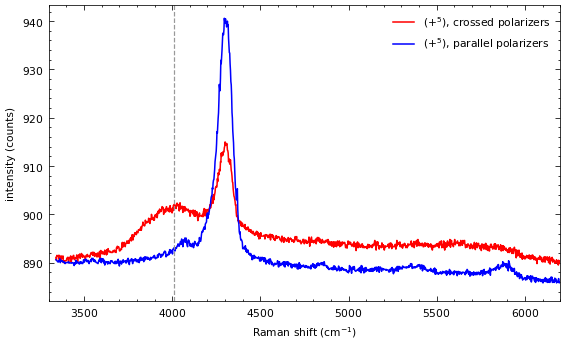

In [6]:
ERS_PEAK = 4008   # cm^-1, -1 -> +1 ERS transition of the (+5) stacking
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(crossed[:, 0], crossed[:, 1], color='red', lw=1, label='$(+^5)$, crossed polarizers')
ax.plot(parallel[:, 0], parallel[:, 1], color='blue', lw=1, label='$(+^5)$, parallel polarizers')
ax.axvline(ERS_PEAK, color='0.6', ls='--', lw=0.8)
ax.set_xlabel('Raman shift (cm$^{-1}$)'); ax.set_ylabel('intensity (counts)')
ax.set_xlim(3300, 6200)
ax.legend(frameon=False)
plt.show()